# Task 3: Predict flow for unseen pumps (Case 2, M4)

**Owner:** Ofri

**Task:** Predict flow using the features available in the case 2 data sets (and any combinations of
these features that you deem relevant). Choose any machine learning model you wish (noted as M4),
and try to get the most accurate prediction possible. Report the test errors of your best-performing
model and argue for your choice of performance metrics. Include a flow versus error plot.
Discuss the hyperparameters of the model, including training and hyperparameter selection details.

- Suggestion 1: Drop the column `elapsed_s` as a feature.
- Suggestion 2: Hold out all data points of a pump together (`GroupKFold`) to avoid data leakage.

**Plan for this notebook**
1. Look at the data, especially how many transient rows exist and whether they behave differently.
2. Choose performance metrics.
3. Set up cross-validation that holds out whole pumps (`GroupKFold`, groups = `pump_id`).
4. Feature selection: start from the case 1 features (n, P, Δp), then add each extra feature
   (operating state, current, temperature) and keep it only if the CV error improves.
5. Operating state hypothesis: compare (A) no state info, (B) state as a 0/1 feature,
   (C) two separate models for stable and transient rows.
6. Team plan: StandardScaler → PCA → model, choosing the number of components k with grouped CV,
   compared against the hand-picked features.
7. Tune the hyperparameters of the chosen model (M4) with grouped CV.
8. Fit the final model on all of `train2.csv`, evaluate once on `test2.csv`, plot error versus flow.
9. Ideas for extensions and alternatives.

In [1]:
import sys
sys.path.append("..")  # so we can import from src/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src.data import load_case2, add_features, TARGET

figures_folder = "../report/figures/"

## 1. Load the data

In [2]:
train_data, test_data = load_case2()
train_data, test_data = add_features(train_data), add_features(test_data)

print("Training data:", train_data.shape)
print("Test data:", test_data.shape)
print("Pumps in training:", sorted(train_data["pump_id"].unique()))
print("Pumps in test:", sorted(test_data["pump_id"].unique()))
print("Pumps in both:", set(train_data["pump_id"]) & set(test_data["pump_id"]))
print("Missing values in training data:", train_data.isna().sum().sum())
print("Missing values in test data:", test_data.isna().sum().sum())
train_data.head()

Training data: (59950, 15)
Test data: (119900, 15)
Pumps in training: ['99223362_model_01', '99223362_model_02', '99223362_model_03', '99223362_model_04', '99223362_model_05']
Pumps in test: ['99223362_model_06', '99223362_model_07', '99223362_model_08', '99223362_model_09', '99223362_model_10', '99223362_model_11', '99223362_model_12', '99223362_model_13', '99223362_model_14', '99223362_model_15']
Pumps in both: set()
Missing values in training data: 0
Missing values in test data: 0


,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,measured_head_m,current_a,torque_nm,temperature_c,flow_m3_h,speed_krpm,power_kw,pressure_difference_bar
0,99223362_model_01,0.0,stable,3221.860983,355.670823,2.412831,3.164026,7.671249,0.568770,1.029636,27.618585,5.71711,3.221861,0.355671,0.751195
1,99223362_model_01,1.0,stable,3198.279924,346.603569,2.423269,3.174624,7.672882,0.594010,1.057619,27.656450,5.71711,3.198280,0.346604,0.751355
2,99223362_model_01,2.0,stable,3197.314725,355.093283,2.302593,3.190288,9.065196,0.572038,1.028020,27.124331,5.71711,3.197315,0.355093,0.887695
3,99223362_model_01,3.0,stable,3187.103203,346.438509,2.345914,3.102848,7.729854,0.599680,1.047076,27.939147,5.71711,3.187103,0.346439,0.756934
4,99223362_model_01,4.0,stable,3212.059205,358.906087,2.343708,3.098729,7.710320,0.590551,1.063113,27.277784,5.71711,3.212059,0.358906,0.755021


In [3]:
# add_features (src/data.py) already added speed_krpm, power_kw and pressure_difference_bar, as in Task 1.
# Here we also add a 0/1 version of the operating state.
for dataset in [train_data, test_data]:
    dataset["is_transient"] = (dataset["operating_state"] == "transient").astype(int)

target_name = TARGET
y_train = train_data[target_name]
y_test = test_data[target_name]
pump_groups = train_data["pump_id"]  # used only to build the CV folds, never as a feature

train_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
elapsed_s,59950.0,5994.500,3461.244,0.000,2997.000,5994.500,8992.000,11989.000
speed_rpm,59950.0,2502.029,824.423,988.945,1807.310,2500.068,3196.285,4076.533
power_w,59950.0,307.221,249.526,21.441,105.219,230.926,447.625,1176.804
inlet_pressure_bar,59950.0,1.753,0.397,0.916,1.430,1.761,2.074,2.566
outlet_pressure_bar,59950.0,2.189,0.494,0.994,1.836,2.183,2.535,3.735
measured_head_m,59950.0,4.455,3.054,-1.959,1.962,3.786,6.489,14.231
current_a,59950.0,0.504,0.409,0.036,0.173,0.379,0.735,1.907
torque_nm,59950.0,1.007,0.560,0.205,0.546,0.879,1.360,2.761
temperature_c,59950.0,26.759,1.184,22.405,26.211,27.013,27.579,29.746
flow_m3_h,59950.0,12.667,8.442,0.067,6.060,11.133,17.941,42.203


## 2. Exploratory look at the operating state

First step of the hypothesis: count the transient rows per pump. If there are only a few, a separate
transient model would have too little data to learn from.

In [4]:
print("Training set: rows per pump and operating state")
print(pd.crosstab(train_data["pump_id"], train_data["operating_state"]))
print("\nTest set: rows per pump and operating state")
print(pd.crosstab(test_data["pump_id"], test_data["operating_state"]))

Training set: rows per pump and operating state
operating_state    stable  transient
pump_id                             
99223362_model_01    6000       5990
99223362_model_02    6000       5990
99223362_model_03    6000       5990
99223362_model_04    6000       5990
99223362_model_05    6000       5990

Test set: rows per pump and operating state
operating_state    stable  transient
pump_id                             
99223362_model_06    6000       5990
99223362_model_07    6000       5990
99223362_model_08    6000       5990
99223362_model_09    6000       5990
99223362_model_10    6000       5990
99223362_model_11    6000       5990
99223362_model_12    6000       5990
99223362_model_13    6000       5990
99223362_model_14    6000       5990
99223362_model_15    6000       5990


In [5]:
# How are the states ordered in time? (look at the first 60 seconds of one pump)
one_pump = train_data[train_data["pump_id"] == train_data["pump_id"].iloc[0]].head(60)
print(one_pump[["elapsed_s", "operating_state", "speed_rpm", "flow_m3_h"]].iloc[::5].to_string(index=False))

 elapsed_s operating_state   speed_rpm  flow_m3_h
       0.0          stable 3221.860983   5.717110
       5.0          stable 3207.459656   5.717110
      10.0       transient 3076.277045   5.717110
      15.0       transient 2351.884015  10.753535
      20.0          stable 1786.844542  15.789960
      25.0          stable 1788.780885  15.789960
      30.0       transient 1750.327711  15.789960
      35.0       transient 1634.931773  10.345459
      40.0          stable 1525.542748   4.900958
      45.0          stable 1521.981419   4.900958
      50.0       transient 1580.846768   4.900958
      55.0       transient 1900.998706   4.651360


**Observation:** each pump has about half stable and half transient rows (6000 vs 5990), and the
states alternate in blocks of 10 seconds. There are plenty of transient rows (about 30,000 in training,
from all 5 pumps), so training a separate transient model is possible.

Rows that are one second apart are almost identical. This is why a normal shuffled `KFold` would leak:
the model would be validated on rows that are near-copies of rows it trained on.

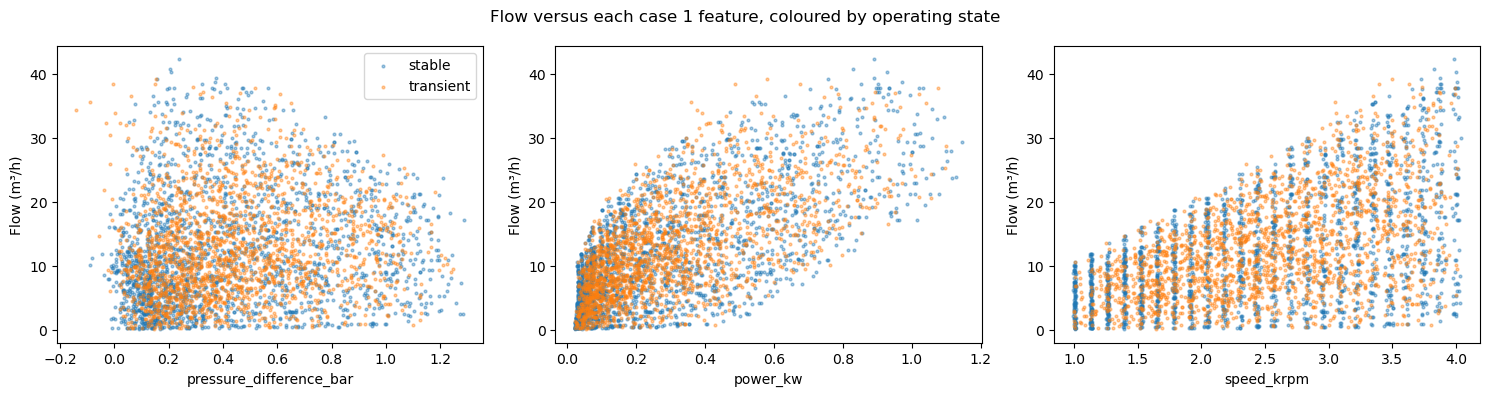

                flow_m3_h        speed_krpm        power_kw         \
                     mean    std       mean    std     mean    std   
operating_state                                                      
stable             12.667  9.048      2.502  0.902    0.317  0.273   
transient          12.666  7.788      2.502  0.739    0.298  0.223   

                pressure_difference_bar         
                                   mean    std  
operating_state                                 
stable                            0.437  0.324  
transient                         0.435  0.271  


In [6]:
# Does the flow relate to the inputs differently in the two states?
plot_sample = train_data.sample(4000, random_state=0)
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, feature in zip(axes, ["pressure_difference_bar", "power_kw", "speed_krpm"]):
    for state, color in [("stable", "tab:blue"), ("transient", "tab:orange")]:
        rows = plot_sample[plot_sample["operating_state"] == state]
        axis.scatter(rows[feature], rows[target_name], s=4, alpha=0.4, color=color, label=state)
    axis.set_xlabel(feature)
    axis.set_ylabel("Flow (m³/h)")
axes[0].legend()
plt.suptitle("Flow versus each case 1 feature, coloured by operating state")
plt.tight_layout()
plt.savefig(figures_folder + "task3_flow_vs_features_by_state.png", dpi=200, bbox_inches="tight")
plt.show()

print(train_data.groupby("operating_state")[
    ["flow_m3_h", "speed_krpm", "power_kw", "pressure_difference_bar"]].agg(["mean", "std"]).round(3))

## 3. Correlation between candidate features

This shows which features carry almost the same information (redundancy):
- power, torque and speed are linked by P = τ·ω
- measured head is Δp divided by a constant (ρg)
- current follows power closely

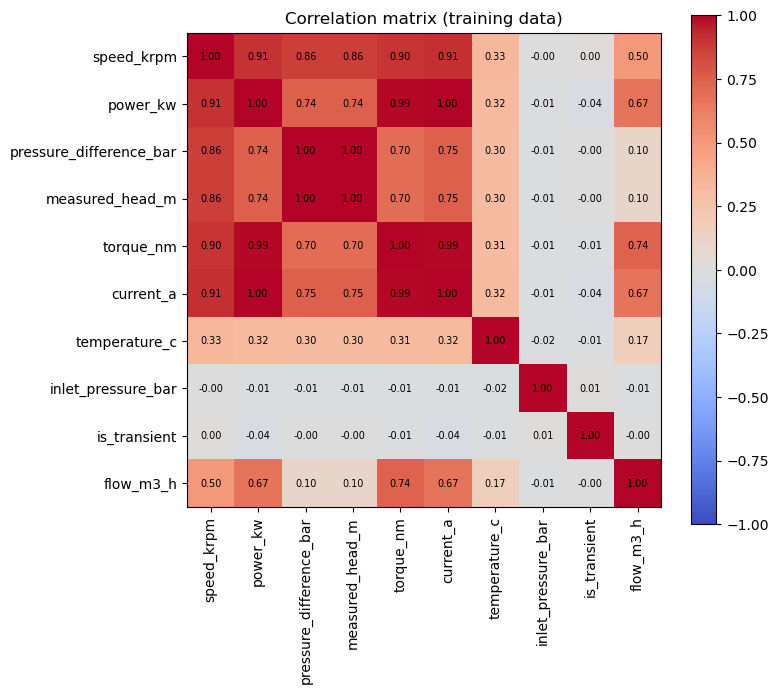

In [7]:
candidate_columns = ["speed_krpm", "power_kw", "pressure_difference_bar", "measured_head_m",
                     "torque_nm", "current_a", "temperature_c", "inlet_pressure_bar",
                     "is_transient", target_name]
correlation_matrix = train_data[candidate_columns].corr()

figure, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(candidate_columns)), candidate_columns, rotation=90)
axis.set_yticks(range(len(candidate_columns)), candidate_columns)
for i in range(len(candidate_columns)):
    for j in range(len(candidate_columns)):
        axis.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(image)
plt.title("Correlation matrix (training data)")
plt.tight_layout()
plt.savefig(figures_folder + "task3_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

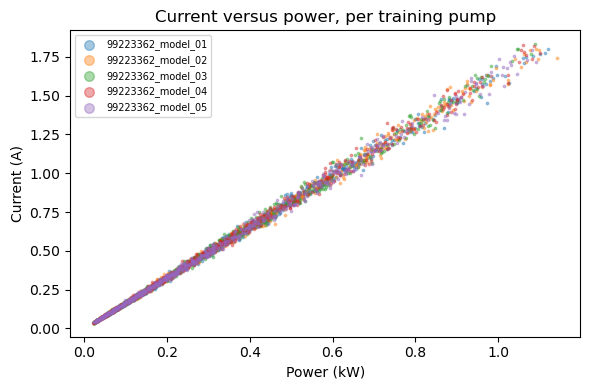

Ratio current / power per pump (mean):
pump_id
99223362_model_01    1.641
99223362_model_02    1.641
99223362_model_03    1.641
99223362_model_04    1.641
99223362_model_05    1.641
dtype: float64


In [8]:
# Current: does the current-to-power relationship look the same for every pump?
# If it differs between pumps (different motors), a model relying on current may not transfer to new pumps.
figure, axis = plt.subplots(figsize=(6, 4))
for pump_id, rows in train_data.groupby("pump_id"):
    rows = rows.sample(800, random_state=0)
    axis.scatter(rows["power_kw"], rows["current_a"], s=3, alpha=0.4, label=pump_id)
axis.set_xlabel("Power (kW)")
axis.set_ylabel("Current (A)")
axis.legend(markerscale=4, fontsize=7)
plt.title("Current versus power, per training pump")
plt.tight_layout()
plt.show()

print("Ratio current / power per pump (mean):")
print((train_data["current_a"] / train_data["power_kw"]).groupby(train_data["pump_id"]).mean().round(3))

## 4. Performance metrics

| Metric | Why it is included |
|---|---|
| **RMSE** (m³/h) | Main metric for all CV decisions, same as Task 1. Same units as the flow, and it punishes large errors strongly, which matters because a big misreading of the flow is worse than several small ones. |
| **MAE** (m³/h) | Easy to explain: "on average the prediction is off by X m³/h". Less sensitive to a few large errors, so comparing it to RMSE tells us whether errors are spread evenly or dominated by a few big misses. |
| **R²** | Unit-free share of the variation in flow explained. Useful for comparing with case 1. |
| **Relative error for Q ≥ 1 m³/h** (%) | A 1 m³/h error is large at Q = 2 but small at Q = 40. The usual MAPE explodes because there are rows with flow close to 0 (minimum 0.02 m³/h), so we only compute it where Q ≥ 1. |

We also report the errors **per pump** and **per operating state**, to see whether the model fails on
specific pumps or during transients.

In [9]:
print("Rows with flow below 0.5 m³/h:", (y_train < 0.5).sum(), "of", len(y_train))


def compute_errors(y_true, y_predicted):
    y_true = np.asarray(y_true)
    y_predicted = np.asarray(y_predicted)
    not_tiny_flow = y_true >= 1
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_predicted)),
        "MAE": mean_absolute_error(y_true, y_predicted),
        "R2": r2_score(y_true, y_predicted),
        "relative_error_pct": 100 * np.mean(
            np.abs(y_true[not_tiny_flow] - y_predicted[not_tiny_flow]) / y_true[not_tiny_flow]),
    }

Rows with flow below 0.5 m³/h: 893 of 59950


## 5. Cross-validation that holds out whole pumps

There are 5 training pumps, so `GroupKFold(n_splits=5)` holds out exactly one pump per fold
(leave-one-pump-out). Each CV score therefore measures how well the model predicts a pump it has
never seen, which is exactly the situation of the test set.

The function below returns the **out-of-fold predictions**: every training row gets a prediction from
a model that did not see its pump. This lets us compute any metric afterwards, and also lets us score
the "two separate models" version on exactly the same rows as the others.

In [10]:
group_cross_validation = GroupKFold(n_splits=5)
cv_splits = list(group_cross_validation.split(train_data, y_train, groups=pump_groups))

for fold_number, (train_rows, validation_rows) in enumerate(cv_splits):
    print(f"Fold {fold_number}: validation pump = {pump_groups.iloc[validation_rows].unique()}")


def out_of_fold_predictions(make_model, feature_names, split_by_state=False):
    # split_by_state=True trains one model on stable rows and another on transient rows,
    # and predicts each validation row with the model for its own state.
    predictions = np.zeros(len(train_data))
    for train_rows, validation_rows in cv_splits:
        fold_train = train_data.iloc[train_rows]
        fold_validation = train_data.iloc[validation_rows]
        if not split_by_state:
            model = make_model()
            model.fit(fold_train[feature_names], fold_train[target_name])
            predictions[validation_rows] = model.predict(fold_validation[feature_names])
        else:
            for state in ["stable", "transient"]:
                state_train = fold_train[fold_train["operating_state"] == state]
                state_mask = (fold_validation["operating_state"] == state).to_numpy()
                model = make_model()
                model.fit(state_train[feature_names], state_train[target_name])
                predictions[validation_rows[state_mask]] = model.predict(
                    fold_validation.loc[state_mask, feature_names])
    return predictions


def cv_summary(predictions):
    # Overall errors, plus RMSE per held-out pump (mean and spread over the 5 folds)
    summary = compute_errors(y_train, predictions)
    rmse_per_pump = [np.sqrt(mean_squared_error(y_train.iloc[rows], predictions[rows]))
                     for _, rows in cv_splits]
    summary["RMSE_std_over_pumps"] = np.std(rmse_per_pump)
    return summary

Fold 0: validation pump = ['99223362_model_05']
Fold 1: validation pump = ['99223362_model_04']
Fold 2: validation pump = ['99223362_model_03']
Fold 3: validation pump = ['99223362_model_02']
Fold 4: validation pump = ['99223362_model_01']


## 6. Choosing the model (M4)

Candidates:
- **Baseline:** polynomial linear regression (degree 3), the best model from Task 1.
- **M4: Gradient boosting** (`HistGradientBoostingRegressor`). It builds many small decision trees,
  each one correcting the errors of the previous ones. Reasons for choosing it:
  - The relationship between flow and the inputs is nonlinear (we saw this in Tasks 0–2), and boosting
    finds nonlinear effects and interactions by itself, without us choosing polynomial terms.
  - It is fast on 60,000 rows (it bins the features into histograms), so grouped CV and tuning are cheap.
  - It does not need feature scaling, and redundant features do not make it unstable like they do in
    linear regression.

We start with the case 1 features and default-like hyperparameters, and tune them later.

In [11]:
case1_features = ["speed_krpm", "power_kw", "pressure_difference_bar"]


def make_linear_baseline():
    return make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(),
                         LinearRegression())


def make_boosting(pca_components=None, **hyperparameters):
    # Returns a function that builds a fresh, untrained model (a new one is needed for every CV fold).
    # With pca_components set, the inputs are first scaled and reduced with PCA (used in section 9).
    # Scaler and PCA sit inside the pipeline, so in CV they are fitted on the training pumps only.
    settings = dict(learning_rate=0.1, max_iter=300, max_leaf_nodes=31,
                    min_samples_leaf=20, random_state=42)
    settings.update(hyperparameters)

    def make_model():
        booster = HistGradientBoostingRegressor(**settings)
        if pca_components is None:
            return booster
        return make_pipeline(StandardScaler(), PCA(n_components=pca_components), booster)
    return make_model


model_comparison = {}
for model_name, make_model in [("Linear regression, degree 3", make_linear_baseline),
                               ("Gradient boosting (M4)", make_boosting())]:
    model_comparison[model_name] = cv_summary(out_of_fold_predictions(make_model, case1_features))

pd.DataFrame(model_comparison).T.round(3)

C:\Users\Ofri\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Ofri\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Ofri\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Ofri\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

,RMSE,MAE,R2,relative_error_pct,RMSE_std_over_pumps
"Linear regression, degree 3",1.980,1.524,0.945,16.337,0.234
Gradient boosting (M4),1.744,1.323,0.957,12.731,0.228


## 7. Feature selection with grouped CV

Start from the case 1 features (n, P, Δp). Then add each extra feature **one at a time** and see whether
the CV RMSE on held-out pumps improves. Afterwards we combine the ones that helped.

Features that were left out on purpose (logic, see the correlation matrix):
- `elapsed_s`: a clock, not a property of the pump (assignment suggestion 1)
- `pump_id`: the test pumps are all new, so the ID carries no usable information
- `measured_head_m`: Δp divided by a constant, so it duplicates Δp
- `torque_nm`: duplicates power and speed (P = τ·ω)

In [12]:
extra_features = ["is_transient", "current_a", "temperature_c"]

feature_results = {"case 1 features": cv_summary(out_of_fold_predictions(make_boosting(), case1_features))}
for extra in extra_features:
    feature_names = case1_features + [extra]
    feature_results["+ " + extra] = cv_summary(out_of_fold_predictions(make_boosting(), feature_names))

feature_results_table = pd.DataFrame(feature_results).T
feature_results_table.round(3)

,RMSE,MAE,R2,relative_error_pct,RMSE_std_over_pumps
case 1 features,1.744,1.323,0.957,12.731,0.228
+ is_transient,1.740,1.321,0.958,12.720,0.230
+ current_a,1.695,1.280,0.960,12.004,0.241
+ temperature_c,1.923,1.481,0.948,13.881,0.170


In [13]:
# Keep the extra features that lowered the CV RMSE compared to the case 1 features,
# then check that the combination is at least as good as the best single addition.
baseline_rmse = feature_results_table.loc["case 1 features", "RMSE"]
helpful_features = [extra for extra in extra_features
                    if feature_results_table.loc["+ " + extra, "RMSE"] < baseline_rmse]
print("Extra features that helped:", helpful_features)

combined_features = case1_features + helpful_features
combined_summary = cv_summary(out_of_fold_predictions(make_boosting(), combined_features))
print("Combined feature set:", combined_features)
print({name: round(value, 3) for name, value in combined_summary.items()})

best_single_name = feature_results_table["RMSE"].idxmin()
if combined_summary["RMSE"] <= feature_results_table["RMSE"].min():
    selected_features = combined_features
else:
    selected_features = case1_features + ([best_single_name[2:]] if best_single_name.startswith("+ ") else [])
print("\nSelected features:", selected_features)

Extra features that helped: ['is_transient', 'current_a']


Combined feature set: ['speed_krpm', 'power_kw', 'pressure_difference_bar', 'is_transient', 'current_a']
{'RMSE': np.float64(1.698), 'MAE': 1.283, 'R2': 0.96, 'relative_error_pct': np.float64(12.035), 'RMSE_std_over_pumps': np.float64(0.242)}

Selected features: ['speed_krpm', 'power_kw', 'pressure_difference_bar', 'current_a']


## 8. Operating state hypothesis: one model or two?

Three versions, all scored on the **same** held-out rows with the same folds:
- **A:** one model, no state information
- **B:** one model, with `is_transient` as a 0/1 feature
- **C:** two separate models (stable and transient), each validation row predicted by the model for its state

For each version we report the overall error and the error on stable and on transient rows separately.

In [14]:
features_without_state = [name for name in selected_features if name != "is_transient"]
features_with_state = features_without_state + ["is_transient"]

state_versions = {
    "A: one model, no state": out_of_fold_predictions(make_boosting(), features_without_state),
    "B: one model, state as feature": out_of_fold_predictions(make_boosting(), features_with_state),
    "C: two separate models": out_of_fold_predictions(make_boosting(), features_without_state,
                                                      split_by_state=True),
}

stable_rows = (train_data["operating_state"] == "stable").to_numpy()
state_results = {}
for version_name, predictions in state_versions.items():
    state_results[version_name] = {
        "RMSE overall": np.sqrt(mean_squared_error(y_train, predictions)),
        "RMSE stable": np.sqrt(mean_squared_error(y_train[stable_rows], predictions[stable_rows])),
        "RMSE transient": np.sqrt(mean_squared_error(y_train[~stable_rows], predictions[~stable_rows])),
        "MAE overall": mean_absolute_error(y_train, predictions),
    }
state_results_table = pd.DataFrame(state_results).T
state_results_table.round(3)

,RMSE overall,RMSE stable,RMSE transient,MAE overall
"A: one model, no state",1.695,1.694,1.697,1.280
"B: one model, state as feature",1.698,1.696,1.700,1.283
C: two separate models,1.716,1.730,1.702,1.296


In [15]:
best_state_version = state_results_table["RMSE overall"].idxmin()
print("Best version by CV RMSE:", best_state_version)

# The two-model version only replaces the one-model versions if it is clearly better (more than 2 %),
# because it is more complex and each model sees only half the data.
one_model_best = state_results_table.loc[["A: one model, no state", "B: one model, state as feature"],
                                         "RMSE overall"].min()
use_separate_models = state_results_table.loc["C: two separate models", "RMSE overall"] < 0.98 * one_model_best
if use_separate_models:
    final_features = features_without_state
elif state_results_table.loc["B: one model, state as feature", "RMSE overall"] < \
        state_results_table.loc["A: one model, no state", "RMSE overall"]:
    final_features = features_with_state
else:
    final_features = features_without_state
print("Use two separate models:", use_separate_models)
print("Final features:", final_features)

Best version by CV RMSE: A: one model, no state
Use two separate models: False
Final features: ['speed_krpm', 'power_kw', 'pressure_difference_bar', 'current_a']


## 9. PCA: StandardScaler → PCA → model (team plan)

Instead of choosing features by hand, give the model **all** sensor features and let PCA compress them
into k components. PCA finds the directions in which the (scaled) features vary the most, so groups of
redundant features (power/torque/current, Δp/head) are merged into one component each.

- The scaler is needed because PCA is driven by variance: without scaling, the feature with the
  largest numbers would dominate.
- Scaler and PCA are inside the pipeline, so in each fold they are fitted on the training pumps only.
- k is chosen with the same leave-one-pump-out CV, and the best k is compared to the hand-picked
  features from sections 7 and 8.
- `is_transient` is left out of PCA, because it is a 0/1 label rather than a measurement.

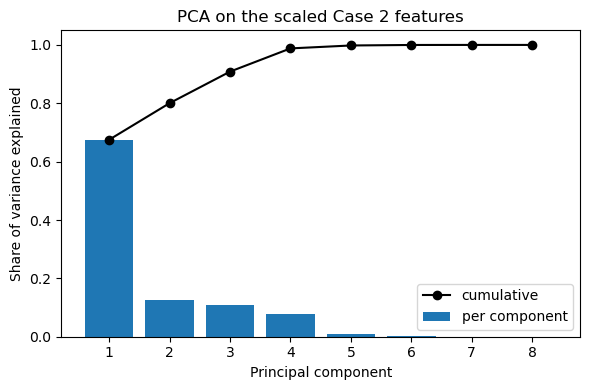

Cumulative explained variance: [0.675 0.8   0.909 0.988 0.998 1.    1.    1.   ]


In [16]:
pca_features = ["speed_krpm", "power_kw", "pressure_difference_bar", "inlet_pressure_bar",
                "measured_head_m", "torque_nm", "current_a", "temperature_c"]

# Explained variance on the scaled training data (for the plot only, not used for any decision)
scaled_training_features = StandardScaler().fit_transform(train_data[pca_features])
explained_variance = PCA().fit(scaled_training_features).explained_variance_ratio_

figure, axis = plt.subplots(figsize=(6, 4))
component_numbers = np.arange(1, len(pca_features) + 1)
axis.bar(component_numbers, explained_variance, label="per component")
axis.plot(component_numbers, np.cumsum(explained_variance), "o-", color="black", label="cumulative")
axis.set_xlabel("Principal component")
axis.set_ylabel("Share of variance explained")
axis.set_title("PCA on the scaled Case 2 features")
axis.legend()
plt.tight_layout()
plt.savefig(figures_folder + "task3_pca_explained_variance.png", dpi=200, bbox_inches="tight")
plt.show()
print("Cumulative explained variance:", np.round(np.cumsum(explained_variance), 3))

In [17]:
pca_results = {}
for number_of_components in range(1, len(pca_features) + 1):
    predictions = out_of_fold_predictions(make_boosting(pca_components=number_of_components),
                                          pca_features, split_by_state=use_separate_models)
    pca_results[number_of_components] = cv_summary(predictions)

pca_results_table = pd.DataFrame(pca_results).T
pca_results_table.index.name = "k (components)"
pca_results_table.round(3)

,RMSE,MAE,R2,relative_error_pct,RMSE_std_over_pumps
k (components),,,,,
1,7.370,5.899,0.238,81.484,0.390
2,7.428,5.923,0.226,81.407,0.382
3,7.553,6.180,0.200,88.190,0.525
4,2.718,2.196,0.896,28.397,0.483
5,2.387,1.781,0.920,20.340,0.683
6,2.321,1.738,0.924,19.073,0.626
7,2.302,1.731,0.926,18.902,0.596
8,2.320,1.743,0.924,18.940,0.616


In [18]:
best_number_of_components = int(pca_results_table["RMSE"].idxmin())
best_pca_rmse = pca_results_table["RMSE"].min()
hand_picked_rmse = cv_summary(out_of_fold_predictions(make_boosting(), final_features,
                                                      split_by_state=use_separate_models))["RMSE"]
print(f"Best PCA: k = {best_number_of_components}, CV RMSE = {best_pca_rmse:.3f}")
print(f"Hand-picked features {final_features}: CV RMSE = {hand_picked_rmse:.3f}")

# Keep whichever approach has the lower CV RMSE for tuning and the final model.
use_pca = best_pca_rmse < hand_picked_rmse
if use_pca:
    final_features = pca_features
    final_pca_components = best_number_of_components
else:
    final_pca_components = None
print("Use PCA:", use_pca)

Best PCA: k = 7, CV RMSE = 2.302
Hand-picked features ['speed_krpm', 'power_kw', 'pressure_difference_bar', 'current_a']: CV RMSE = 1.695
Use PCA: False


## 10. Hyperparameter tuning for M4

Hyperparameters of gradient boosting that we tune:
- `learning_rate`: how much each new tree corrects the previous ones. Smaller is more careful but needs more trees.
- `max_iter`: number of trees.
- `max_leaf_nodes`: size of each tree, i.e. how complex the interactions each tree can model.
- `min_samples_leaf`: the minimum number of rows in a leaf. Larger values smooth the model and reduce
  overfitting to the specific training pumps.

Each combination is scored with the same leave-one-pump-out CV. The test set is not used.

In [19]:
hyperparameter_grid = [
    dict(learning_rate=learning_rate, max_iter=max_iter, max_leaf_nodes=max_leaf_nodes,
         min_samples_leaf=min_samples_leaf)
    for learning_rate, max_iter in [(0.1, 300), (0.05, 600)]
    for max_leaf_nodes in [15, 31, 63]
    for min_samples_leaf in [20, 200]
]

tuning_results = []
start_time = time.time()
for hyperparameters in hyperparameter_grid:
    predictions = out_of_fold_predictions(
        make_boosting(pca_components=final_pca_components, **hyperparameters), final_features,
        split_by_state=use_separate_models)
    tuning_results.append({**hyperparameters, **cv_summary(predictions)})
print(f"Tuning took {time.time() - start_time:.0f} seconds")

tuning_table = pd.DataFrame(tuning_results).sort_values("RMSE")
tuning_table.round(3)

Tuning took 342 seconds


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,RMSE,MAE,R2,relative_error_pct,RMSE_std_over_pumps
10,0.05,600,63,20,1.670,1.254,0.961,11.681,0.241
11,0.05,600,63,200,1.674,1.257,0.961,11.710,0.250
4,0.10,300,63,20,1.674,1.259,0.961,11.769,0.242
5,0.10,300,63,200,1.676,1.260,0.961,11.794,0.250
8,0.05,600,31,20,1.693,1.278,0.960,11.955,0.242
2,0.10,300,31,20,1.695,1.280,0.960,12.004,0.241
9,0.05,600,31,200,1.705,1.288,0.959,11.991,0.250
3,0.10,300,31,200,1.707,1.290,0.959,12.051,0.245
6,0.05,600,15,20,1.733,1.315,0.958,12.293,0.244
0,0.10,300,15,20,1.743,1.325,0.957,12.447,0.241


In [20]:
best_hyperparameters = tuning_table.iloc[0][["learning_rate", "max_iter", "max_leaf_nodes",
                                             "min_samples_leaf"]].to_dict()
best_hyperparameters = {"learning_rate": float(best_hyperparameters["learning_rate"]),
                        "max_iter": int(best_hyperparameters["max_iter"]),
                        "max_leaf_nodes": int(best_hyperparameters["max_leaf_nodes"]),
                        "min_samples_leaf": int(best_hyperparameters["min_samples_leaf"])}
print("Best hyperparameters:", best_hyperparameters)
print("CV RMSE with them:", round(tuning_table.iloc[0]["RMSE"], 3),
      "+/-", round(tuning_table.iloc[0]["RMSE_std_over_pumps"], 3), "(spread over held-out pumps)")

Best hyperparameters: {'learning_rate': 0.05, 'max_iter': 600, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}
CV RMSE with them: 1.67 +/- 0.241 (spread over held-out pumps)


## 11. Final model: train on all of `train2.csv`, evaluate once on `test2.csv`

In [21]:
make_final_model = make_boosting(pca_components=final_pca_components, **best_hyperparameters)

if use_separate_models:
    predicted_flow = np.zeros(len(test_data))
    for state in ["stable", "transient"]:
        state_train = train_data[train_data["operating_state"] == state]
        state_mask = (test_data["operating_state"] == state).to_numpy()
        model = make_final_model()
        model.fit(state_train[final_features], state_train[target_name])
        predicted_flow[state_mask] = model.predict(test_data.loc[state_mask, final_features])
else:
    final_model = make_final_model()
    final_model.fit(train_data[final_features], y_train)
    predicted_flow = final_model.predict(test_data[final_features])

# Baseline for comparison: Task 1 style linear regression on the case 1 features
baseline_model = make_linear_baseline()
baseline_model.fit(train_data[case1_features], y_train)
baseline_predicted_flow = baseline_model.predict(test_data[case1_features])

test_results = pd.DataFrame({
    "Linear regression baseline": compute_errors(y_test, baseline_predicted_flow),
    "M4 gradient boosting": compute_errors(y_test, predicted_flow),
}).T
print("Final features:", final_features)
print("PCA components:", final_pca_components)
print("Two separate models:", use_separate_models)
print("Hyperparameters:", best_hyperparameters)
test_results.round(3)

Final features: ['speed_krpm', 'power_kw', 'pressure_difference_bar', 'current_a']
PCA components: None
Two separate models: False
Hyperparameters: {'learning_rate': 0.05, 'max_iter': 600, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


,RMSE,MAE,R2,relative_error_pct
Linear regression baseline,2.061,1.633,0.938,18.943
M4 gradient boosting,1.672,1.323,0.959,14.521


In [22]:
# Errors per operating state and per test pump
test_data["predicted_flow"] = predicted_flow
test_data["error"] = test_data[target_name] - test_data["predicted_flow"]

per_state = test_data.groupby("operating_state").apply(
    lambda rows: pd.Series(compute_errors(rows[target_name], rows["predicted_flow"])), include_groups=False)
per_pump = test_data.groupby("pump_id").apply(
    lambda rows: pd.Series(compute_errors(rows[target_name], rows["predicted_flow"])), include_groups=False)
print("Test errors per operating state")
print(per_state.round(3))
print("\nTest errors per pump")
print(per_pump.round(3))

Test errors per operating state
                  RMSE    MAE     R2  relative_error_pct
operating_state                                         
stable           1.646  1.296  0.966              14.740
transient        1.698  1.350  0.951              14.309

Test errors per pump
                    RMSE    MAE     R2  relative_error_pct
pump_id                                                   
99223362_model_06  1.509  1.246  0.966              15.889
99223362_model_07  1.450  1.122  0.972              11.152
99223362_model_08  1.757  1.431  0.950              15.765
99223362_model_09  1.525  1.165  0.970              11.064
99223362_model_10  1.726  1.317  0.964              11.407
99223362_model_11  2.249  1.968  0.912              25.093
99223362_model_12  1.285  0.959  0.977              10.067
99223362_model_13  1.468  1.195  0.966              14.313
99223362_model_14  1.589  1.208  0.959              11.777
99223362_model_15  1.950  1.618  0.938              18.763


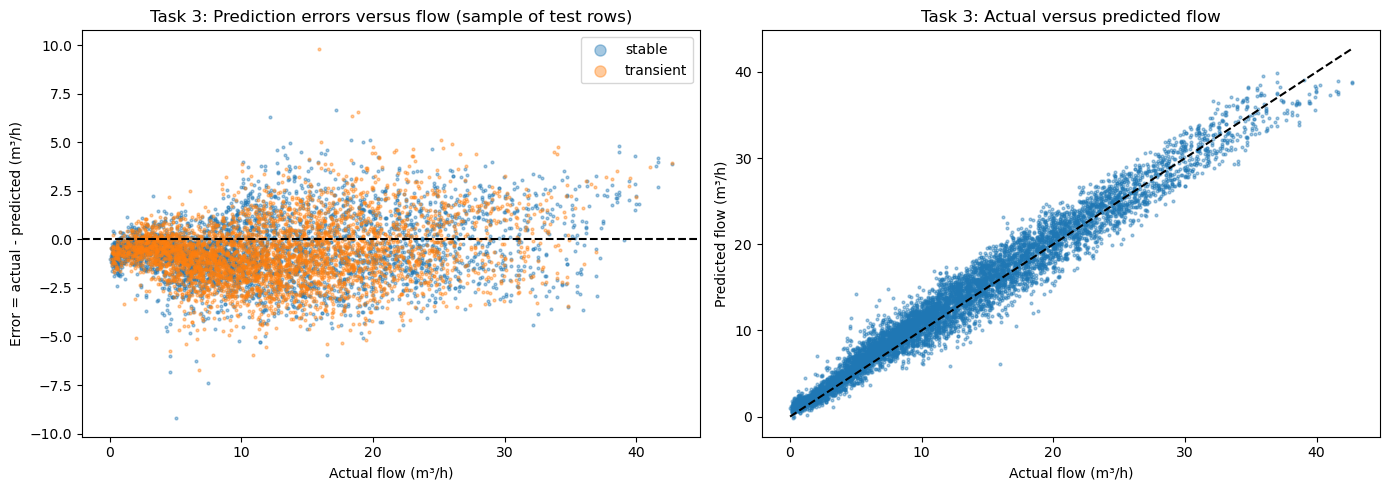

In [23]:
# Flow versus error plot (required), coloured by operating state
plot_rows = test_data.sample(8000, random_state=0)
figure, axes = plt.subplots(1, 2, figsize=(14, 5))

for state, color in [("stable", "tab:blue"), ("transient", "tab:orange")]:
    rows = plot_rows[plot_rows["operating_state"] == state]
    axes[0].scatter(rows[target_name], rows["error"], s=4, alpha=0.4, color=color, label=state)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Actual flow (m³/h)")
axes[0].set_ylabel("Error = actual - predicted (m³/h)")
axes[0].set_title("Task 3: Prediction errors versus flow (sample of test rows)")
axes[0].legend(markerscale=4)

axes[1].scatter(plot_rows[target_name], plot_rows["predicted_flow"], s=4, alpha=0.4)
limits = [0, max(plot_rows[target_name].max(), plot_rows["predicted_flow"].max())]
axes[1].plot(limits, limits, "k--")
axes[1].set_xlabel("Actual flow (m³/h)")
axes[1].set_ylabel("Predicted flow (m³/h)")
axes[1].set_title("Task 3: Actual versus predicted flow")
plt.tight_layout()
plt.savefig(figures_folder + "task3_error_vs_flow.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
# Is the error larger for some flow ranges? Mean absolute error per flow bin.
flow_bins = pd.cut(test_data[target_name], bins=[0, 2, 5, 10, 15, 20, 30, 45])
print(test_data.groupby(flow_bins, observed=True)["error"].agg(
    rows="size", mean_error="mean", MAE=lambda errors: errors.abs().mean()).round(3))

            rows  mean_error    MAE
flow_m3_h                          
(0, 2]      8535      -0.628  0.679
(2, 5]     15935      -0.643  0.797
(5, 10]    30270      -1.047  1.297
(10, 15]   25262      -0.808  1.559
(15, 20]   17614      -0.522  1.542
(20, 30]   17880      -0.153  1.467
(30, 45]    4404       0.593  1.834


## 12. Notes for the report

- **Leakage:** all model choices (features, one vs two models, PCA, hyperparameters) were made with
  leave-one-pump-out CV on `train2.csv`. The test set was used once, at the end.
- **Compare CV and test errors:** if the test RMSE is close to the CV RMSE, the grouped CV was a good
  estimate of performance on new pumps. If it is much higher, the 10 test pumps differ from the 5 training pumps.
- **Spread over pumps** (`RMSE_std_over_pumps`): with only 5 training pumps the CV estimate is noisy,
  so small differences between feature sets or hyperparameters may not be meaningful.
- **Per-pump test errors:** look for pumps with much larger errors and check whether their inputs fall
  outside the range seen in training.

## 13. Extensions and alternative approaches

**Features**
- **Lag / change features for transients.** Rows are one second apart and the state alternates every
  10 seconds. During a transient the flow may lag behind speed and pressure changes. Add, per pump and
  sorted by `elapsed_s`: the change since the previous second (`diff`), the value a few seconds ago, or a
  short rolling mean. `elapsed_s` is then used only to order the rows, not as a feature. Compute these
  within each pump so values never cross from one pump to another.
- **Physics-based features (affinity laws).** For centrifugal pumps, Q scales with n, Δp with n², and
  P with n³. Features such as Δp/n², P/n³ and Q/n (predict Q/n and multiply back) can make different
  speeds look alike, which may help generalise to new pumps.
- **Use the Task 0 equation.** Task 0 gives P as a polynomial in n and Q. For a given n and P you can
  solve it for Q and use that estimate as an extra feature, or as a baseline model.
- **Recheck current and torque** with grouped CV instead of dropping them by logic only.

**Models**
- **Random forest or extra trees** as a second M4 candidate to compare against boosting.
- **Neural network** (your M2 from Task 2, or `MLPRegressor`) with scaled inputs. It gives a smooth
  function, which may extrapolate better than trees to pumps that operate slightly outside the
  training range (trees predict a constant outside the training range).
- **Sequence models** (1D CNN or LSTM over a sliding window of seconds) to model transients directly.
- **Ensemble:** average the predictions of boosting and a neural network.

**Training and tuning**
- **Larger or random hyperparameter search** (`RandomizedSearchCV` with `cv=GroupKFold`, `groups=pump_id`),
  or early stopping on a held-out pump to choose the number of trees.
- **Loss function:** if relative error matters most to the customer, train on log(flow) or use a loss
  that weighs low flows more.
- **Prediction intervals:** quantile gradient boosting (`loss="quantile"`) gives a range for each prediction,
  which is useful for a company monitoring pumps.

**Outlook (data collection, for the report)**
- More training pumps would make the model generalise better, since 5 pumps is a small sample of pump-to-pump variation.
- Record pump characteristics (impeller size, model, motor efficiency) so the model can explain why pumps differ.
- Calibrate each customer pump briefly with a flow meter at installation, then use that data to adjust the model.